## Feature selection

Why would it even be necessary to select features? To some, this idea may seem counterintuitive, but there are at least two important reasons to get rid of unimportant features. The first is clear to every engineer: the more data, the higher the computational complexity. As long as we work with toy datasets, the size of the data is not a problem, but, for real loaded production systems, hundreds of extra features will be quite tangible. The second reason is that some algorithms take noise (non-informative features) as a signal and overfit.

### Statistical approaches

The most obvious candidate for removal is a feature whose value remains unchanged, i.e., it contains no information at all. If we build on this thought, it is reasonable to say that features with low variance are worse than those with high variance. So, one can consider cutting features with variance below a certain threshold.

#### Basado en estadísticos no supervisado

In [1]:
import numpy as np

In [2]:
from sklearn.datasets import make_classification

x_data_generated, y_data_generated = make_classification(random_state=2)
x_data_generated.shape

(100, 20)

## VarianceThreshold

- **¿Qué es?**: Una técnica que elimina características cuya varianza no alcanza un umbral especificado.
- **Funcionamiento**: Calcula la varianza de cada característica y elimina aquellas que no superan el umbral establecido. Esto significa que las características que apenas cambian entre muestras (es decir, tienen baja varianza) se descartarán.
- **Ventajas**: Rápida y fácil de usar, útil cuando las características con baja varianza no son informativas.
- **Limitaciones**: No considera la relación con la variable objetivo, puede eliminar características útiles.


In [3]:
from sklearn.feature_selection import VarianceThreshold

primer_filtro = VarianceThreshold(.7).fit_transform(x_data_generated)
primer_filtro.shape

(100, 20)

In [4]:
primer_filtro = VarianceThreshold(.8).fit_transform(x_data_generated)
primer_filtro.shape

(100, 15)

In [5]:
primer_filtro = VarianceThreshold(.9).fit_transform(x_data_generated)
primer_filtro.shape

(100, 14)

In [6]:
primer_filtro = VarianceThreshold(.99).fit_transform(x_data_generated)
primer_filtro.shape

(100, 11)

#### Basado en estadísticos supervisado

## SelectKBest

- **¿Qué es?**: Selecciona las K mejores características basadas en algún criterio de puntuación.
- **Funcionamiento**: Calcula un puntaje para cada característica en función de algún criterio (como la prueba F para la regresión lineal o la puntuación chi-cuadrado para la clasificación). Luego, selecciona las K características con los puntajes más altos.
- **Ventajas**: Permite seleccionar características en función de su relevancia con respecto a la variable objetivo.
- **Limitaciones**: Puede ser costoso para conjuntos de datos grandes, elección subjetiva de K.


In [7]:
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score

x_data_kbest = SelectKBest(k=5).fit_transform(x_data_generated, y_data_generated)

In [8]:
x_data_kbest.shape

(100, 5)

In [9]:
logit = LogisticRegression(random_state=42)

In [10]:
coss_val_res = cross_val_score(logit, x_data_generated, y_data_generated, cv=5)
np.mean(coss_val_res)

np.float64(0.8800000000000001)

In [11]:
coss_val_res = cross_val_score(logit, x_data_kbest, y_data_generated, cv=5)
np.mean(coss_val_res)

np.float64(0.86)

In [12]:
x_data_varth = VarianceThreshold(.9).fit_transform(x_data_generated)
coss_val_res = cross_val_score(logit, x_data_varth, y_data_generated, cv=5)
np.mean(coss_val_res)

np.float64(0.89)

We can see that our selected features have improved the quality of the classifier. Of course, this example is purely artificial; however, it is worth using for real problems.

#### Supervisado wrapper

## RFE (Recursive Feature Elimination)

- **¿Qué es?**: Elimina recursivamente las características menos importantes hasta alcanzar el número deseado.
- **Funcionamiento**: Entrena un modelo (generalmente un modelo de aprendizaje automático) en todas las características y luego elimina las características con menor importancia. Este proceso se repite hasta que se alcanza el número deseado de características.
- **Ventajas**: Considera la interacción entre características, puede ser más robusto.
- **Limitaciones**: Puede ser costoso computacionalmente, elección del modelo y número de características.


In [13]:
from sklearn.svm import SVC
from sklearn.feature_selection import RFE
from sklearn.datasets import load_digits
import matplotlib.pyplot as plt

digits = load_digits()
X = digits.images.reshape((len(digits.images)), -1)
y = digits.target

In [14]:
X.shape

(1797, 64)

In [15]:
svc = SVC(kernel="linear", C=1)
rfe = RFE(estimator=svc, n_features_to_select=10, step=1)
rfe.fit(X, y)

,"estimator estimator: ``Estimator`` instanceA supervised learning estimator with a ``fit`` method that providesinformation about feature importance(e.g. `coef_`, `feature_importances_`).","SVC(C=1, kernel='linear')"
,"n_features_to_select n_features_to_select: int or float, default=NoneThe number of features to select. If `None`, half of the features areselected. If integer, the parameter is the absolute number of featuresto select. If float between 0 and 1, it is the fraction of features toselect... versionchanged:: 0.24 Added float values for fractions.",10
,"step step: int or float, default=1If greater than or equal to 1, then ``step`` corresponds to the(integer) number of features to remove at each iteration.If within (0.0, 1.0), then ``step`` corresponds to the percentage(rounded down) of features to remove at each iteration.",1
,"verbose verbose: int, default=0Controls verbosity of output.",0
,"importance_getter importance_getter: str or callable, default='auto'If 'auto', uses the feature importance either through a `coef_`or `feature_importances_` attributes of estimator.Also accepts a string that specifies an attribute name/pathfor extracting feature importance (implemented with `attrgetter`).For example, give `regressor_.coef_` in case of:class:`~sklearn.compose.TransformedTargetRegressor` or`named_steps.clf.feature_importances_` in case ofclass:`~sklearn.pipeline.Pipeline` with its last step named `clf`.If `callable`, overrides the default feature importance getter.The callable is passed with the fitted estimator and it shouldreturn importance for each feature... versionadded:: 0.24",'auto'
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only available when `estimator` is a classifier.","ndarray[int64](10,)","[0,1,2,...,7,8,9]"
estimator_ estimator_: ``Estimator`` instanceThe fitted estimator used to select features.,SVC,"SVC(C=1, kernel='linear')"
n_features_ n_features_: intThe number of selected features.,int64,np.int64(10)
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 0.24,int,64
"ranking_ ranking_: ndarray of shape (n_features,)The feature ranking, such that ``ranking_[i]`` corresponds to theranking position of the i-th feature. Selected (i.e., estimatedbest) features are assigned rank 1.","ndarray[int64](64,)","[55,41,22,...,12, 3,37]"


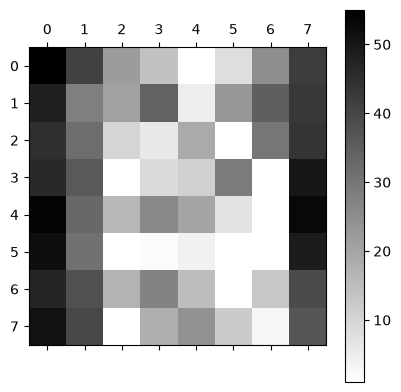

In [16]:
ranking = rfe.ranking_.reshape(digits.images[0].shape)

plt.matshow(ranking, cmap='binary')
plt.colorbar();